# PROYECTO INTEGRADOR: ALERTA POR NIVEL DE RÍO
## IA para predecir el riesgo de desbordamiento

**Materia:** IoT y Cómputo Cognitivo

**Equipo:** Emmanuel Alejandro Paredes Ramírez, Braulio Josue Urzua Santos, Jacqueline del Rosario Gonzales Puga, Kevin Emiliano Alvarez Luna

Universidad de Colima · Ingeniería en Tecnologías de Internet

## Descripción del proyecto
El nodo ESP32 mide cada segundo el nivel del río, la lluvia y la humedad del suelo, y clasifica el riesgo con reglas fijas (bajo, medio, alto). Las reglas solo ven el momento actual.

En este cuaderno se entrena un modelo que predice el riesgo que habrá **dentro de 15 segundos**, para avisar antes que las reglas. Al final el cuaderno se conecta al broker MQTT, recibe las lecturas del nodo en vivo y publica su predicción.

El nodo tiene 3 modos que se eligen desde el tablero:
- **Automático:** deciden las reglas con los sensores.
- **Manual:** los valores y la compuerta los pone el usuario desde el tablero.
- **IA:** decide este modelo. El ESP32 usa el riesgo que predice la IA para el LED, el buzzer y la compuerta.

- **Tipo de problema:** clasificación (3 clases: bajo, medio, alto).
- **Datos:** `dataset_nodo_rio.csv`, 1,808 lecturas de 12 tormentas simuladas (lluvia → humedad → nivel), porque en la maqueta el nivel lo mueve la bomba y no la lluvia.
- **Metas del Canva de datos:** F1 ≥ 0.85 y recall de la clase ALTO ≥ 0.90.

## 1.- Importar librerías

In [1]:
# Libreria para MQTT (en Colab no viene instalada)
!pip -q install paho-mqtt

import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, f1_score, recall_score, roc_curve, roc_auc_score)
import joblib
import os

SEMILLA = 42
CLASES = ['bajo', 'medio', 'alto']

## 2.- Datos

### 2.1 Reglas del nodo
Son las mismas reglas que tiene el firmware del ESP32 (`clasificarRiesgo()`). Nivel en cm reales (0 a 400).

In [2]:
# Reglas del firmware, en el mismo orden
def clasificar_riesgo(nivel, lluvia, humedad):
    if nivel > 250:
        return 2
    if nivel > 200 and lluvia > 70:
        return 2
    if nivel >= 150:
        return 1
    if lluvia > 60 and humedad > 80:
        return 1
    return 0

# Prueba con los casos de la guia del nodo (debe salir 2 2 1 1 0)
print(clasificar_riesgo(300, 0, 0), clasificar_riesgo(220, 75, 40), clasificar_riesgo(220, 50, 40),
      clasificar_riesgo(100, 65, 85), clasificar_riesgo(100, 65, 50))

2 2 1 1 0


### 2.2 Simulador de tormentas
Con este simulador se creó el dataset de la sección 2.3. Cada tormenta dura 2.5 minutos con una lectura por segundo, igual que el nodo.
- La lluvia sube, se mantiene y baja.
- La humedad sube con la lluvia y se seca poco a poco.
- El agua que el suelo ya no absorbe llega al río unos segundos después.
- La compuerta abre en ALTO y cierra abajo de 150 cm, como en la maqueta.
- Se agrega ruido como el de los sensores.

In [3]:
DURACION_S = 150

def una_tormenta(num, rng):
    # Valores al azar de esta tormenta
    pico = rng.choice([0, rng.uniform(20, 60), rng.uniform(60, 100)], p=[0.1, 0.3, 0.6])
    inicio = rng.integers(3, 30)
    subida = rng.integers(8, 30)
    meseta = rng.integers(10, 60)
    bajada = rng.integers(10, 40)
    retraso = rng.integers(4, 11)      # segundos que tarda el agua en llegar al rio
    k = rng.uniform(0.05, 0.14)        # que tan rapido responde el rio
    nivel = rng.uniform(10, 140)
    humedad = rng.uniform(10, 70)
    base = nivel * rng.uniform(0.6, 1.0)
    abierta = False

    lluvias, filas = [], []
    for t in range(DURACION_S):
        # Lluvia
        if t < inicio:
            ll = 0.0
        elif t < inicio + subida:
            ll = pico * (t - inicio) / subida
        elif t < inicio + subida + meseta:
            ll = pico
        elif t < inicio + subida + meseta + bajada:
            ll = pico * (1 - (t - inicio - subida - meseta) / bajada)
        else:
            ll = 0.0
        lluvias.append(ll)

        # Humedad del suelo
        humedad = humedad + 0.024 * ll * (1 - humedad / 100) - 0.02
        humedad = min(max(humedad, 0), 100)

        # Nivel del rio
        ll_retrasada = lluvias[t - retraso] if t >= retraso else 0.0
        entrada = 3.0 * k * ll_retrasada * (0.3 + 0.7 * humedad / 100)
        salida = 0.02 * max(nivel - base, 0)
        if nivel > 320:                 # rebasa la cresta del vertedero
            salida += 0.15 * (nivel - 320)
        if abierta:
            salida += 0.02 * nivel
        nivel = min(max(nivel + entrada - salida, 0), 400)

        # Lo que mide el nodo (con ruido)
        n = min(max(nivel + rng.normal(0, 3), 0), 400)
        l = min(max(ll + rng.normal(0, 2), 0), 100)
        h = min(max(humedad + rng.normal(0, 1.5), 0), 100)

        # Compuerta
        if clasificar_riesgo(n, l, h) == 2:
            abierta = True
        elif nivel < 150:
            abierta = False

        filas.append([num, t, round(n, 1), round(l, 1), round(h, 1)])
    return filas

def generar(n_tormentas, semilla):
    rng = np.random.default_rng(semilla)
    filas = []
    for i in range(n_tormentas):
        filas += una_tormenta(i, rng)
    return pd.DataFrame(filas, columns=['tormenta', 'segundo', 'nivel_cm', 'lluvia_pct', 'humedad_pct'])

### 2.3 Cargar el dataset
`dataset_nodo_rio.csv` tiene 12 tormentas de 2.5 minutos hechas con el simulador (`ia/crear_dataset.py` en el repositorio). Como en un nodo real, trae algunas lecturas vacías (un sensor no respondió) y algunos mensajes repetidos.

Si subiste el archivo a Colab (ícono de carpeta → subir) se usa ese; si no, se descarga del repositorio de GitHub.

In [4]:
ARCHIVO = 'dataset_nodo_rio.csv'
URL = 'https://raw.githubusercontent.com/1Asem7/maqueta-rio-tablero/main/ia/dataset_nodo_rio.csv'

if os.path.exists(ARCHIVO):
    df = pd.read_csv(ARCHIVO)
else:
    df = pd.read_csv(URL)
print('Registros:', df.shape[0], '| Columnas:', df.shape[1])

Registros: 1808 | Columnas: 6


**Lecturas reales (opcional):** la sección 9 guarda las lecturas del nodo en `lecturas_reales.csv`. Para agregarlas al entrenamiento, sube el archivo a Colab y quita los `#` de la celda de abajo (solo se usan las de modo automático; las de modo manual son valores puestos a mano).

In [5]:
# df_real = pd.read_csv('lecturas_reales.csv')
# df_real = df_real[df_real['modo'] == 'auto']
# df_real['tormenta'] = 'real_' + df_real['sesion'].astype(str)
# df = pd.concat([df, df_real[['tormenta', 'segundo', 'nivel_cm', 'lluvia_pct', 'humedad_pct']]], ignore_index=True)

## 3.- Análisis exploratorio

### 3.1 Primeros y últimos registros

In [6]:
df.head(10)

,fecha_hora,tormenta,segundo,nivel_cm,lluvia_pct,humedad_pct
0,2026-11-10 14:00:00,0,0,114.3,1.6,17.8
1,2026-11-10 14:00:01,0,1,114.6,0.9,16.4
2,2026-11-10 14:00:02,0,2,111.8,0.0,18.9
3,2026-11-10 14:00:03,0,3,110.1,0.0,16.6
4,2026-11-10 14:00:04,0,4,113.5,0.0,16.9
5,2026-11-10 14:00:05,0,5,108.3,1.1,18.1
6,2026-11-10 14:00:06,0,6,110.2,4.2,20.8
7,2026-11-10 14:00:07,0,7,107.3,5.7,16.5
8,2026-11-10 14:00:08,0,8,109.9,12.4,17.7
9,2026-11-10 14:00:09,0,9,105.2,11.8,19.1


In [7]:
df.tail(10)

,fecha_hora,tormenta,segundo,nivel_cm,lluvia_pct,humedad_pct
1798,2026-11-21 14:02:20,11,140,51.1,0.0,9.5
1799,2026-11-21 14:02:21,11,141,55.1,1.6,10.2
1800,2026-11-21 14:02:22,11,142,50.5,0.0,6.2
1801,2026-11-21 14:02:23,11,143,51.9,0.0,7.0
1802,2026-11-21 14:02:24,11,144,51.0,1.6,7.8
1803,2026-11-21 14:02:25,11,145,50.8,1.2,8.4
1804,2026-11-21 14:02:26,11,146,50.3,0.0,3.9
1805,2026-11-21 14:02:27,11,147,49.3,0.0,7.3
1806,2026-11-21 14:02:28,11,148,49.8,0.0,5.4
1807,2026-11-21 14:02:29,11,149,53.1,0.9,7.8


### 3.2 Tipos de datos y memoria

In [8]:
# La fecha viene como texto: se pasa a fecha y hora
df['fecha_hora'] = pd.to_datetime(df['fecha_hora'])
df.info(memory_usage='deep')
print('Memoria:', round(df.memory_usage(deep=True).sum() / 1024**2, 2), 'MB')

<class 'pandas.DataFrame'>
RangeIndex: 1808 entries, 0 to 1807
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   fecha_hora   1808 non-null   datetime64[us]
 1   tormenta     1808 non-null   int64         
 2   segundo      1808 non-null   int64         
 3   nivel_cm     1805 non-null   float64       
 4   lluvia_pct   1802 non-null   float64       
 5   humedad_pct  1798 non-null   float64       
dtypes: datetime64[us](1), float64(3), int64(2)
memory usage: 84.9 KB
Memoria: 0.08 MB


### 3.3 Mínimo, media y máximo

In [9]:
df[['nivel_cm', 'lluvia_pct', 'humedad_pct']].describe().loc[['min', 'mean', 'max']]

,nivel_cm,lluvia_pct,humedad_pct
min,27.600000,0.000000,3.900000
mean,126.614681,14.746004,53.575806
max,361.400000,91.200000,84.200000


### 3.4 Valores nulos

In [10]:
# Nulos en texto
print(df.isnull().sum())
print('Duplicados:', df.duplicated().sum())

fecha_hora      0
tormenta        0
segundo         0
nivel_cm        3
lluvia_pct      6
humedad_pct    10
dtype: int64
Duplicados: 8


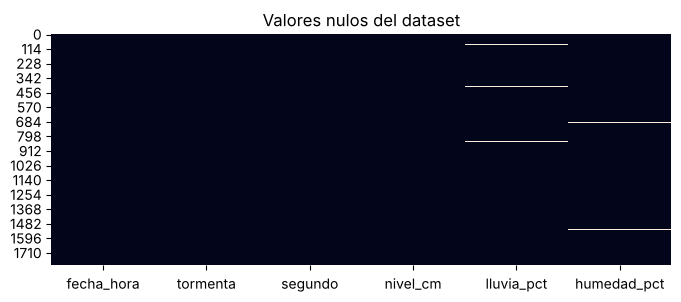

In [11]:
# Nulos en grafica
plt.figure(figsize=(8, 3))
sns.heatmap(df.isnull(), cbar=False)
plt.title('Valores nulos del dataset')
plt.show()

### 3.5 Limpieza
Se quitan los mensajes repetidos. Los nulos no se rellenan con la mediana porque son datos en el tiempo: se usa la lectura anterior de la misma tormenta (un segundo antes).

In [12]:
df = df.drop_duplicates()
df = df.sort_values(['tormenta', 'segundo']).reset_index(drop=True)
columnas_sensor = ['nivel_cm', 'lluvia_pct', 'humedad_pct']
df[columnas_sensor] = df.groupby('tormenta')[columnas_sensor].ffill()

print('Registros despues de limpiar:', df.shape[0])
print('Nulos:', df.isnull().sum().sum(), '| Duplicados:', df.duplicated().sum())

Registros despues de limpiar: 1800
Nulos: 0 | Duplicados: 0


**Comentario:** El dataset trae 19 lecturas vacías (3 de nivel, 6 de lluvia y 10 de humedad) y 8 mensajes repetidos. Se quitaron los repetidos y cada vacío se rellenó con la lectura de un segundo antes de la misma tormenta. Quedaron 1,800 lecturas sin nulos ni duplicados.

### 3.6 Histogramas

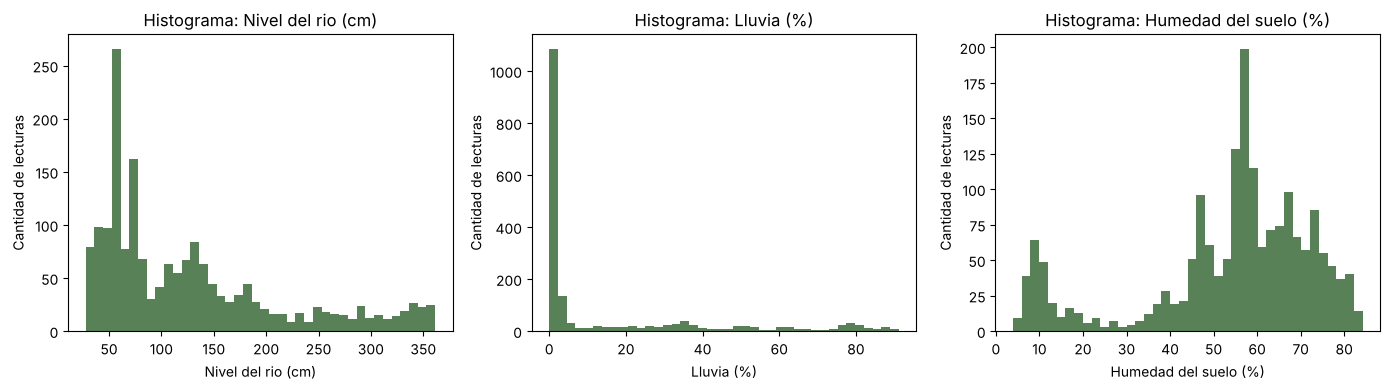

In [13]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for eje, col, nombre in zip(ejes, ['nivel_cm', 'lluvia_pct', 'humedad_pct'],
                            ['Nivel del rio (cm)', 'Lluvia (%)', 'Humedad del suelo (%)']):
    eje.hist(df[col], bins=40, color='#588157')
    eje.set_title('Histograma: ' + nombre)
    eje.set_xlabel(nombre)
    eje.set_ylabel('Cantidad de lecturas')
plt.tight_layout()
plt.show()

**Comentario:** El nivel se concentra entre 60 y 170 cm (río normal) y tiene una cola hasta 360 cm por las crecidas. La lluvia vale casi 0 % en casi la mitad de las lecturas (47 %), porque cada tormenta tiene tiempo seco antes y después. La humedad va de 4 a 84 % y la mitad queda arriba de 57 %.

### 3.7 Una tormenta en el tiempo

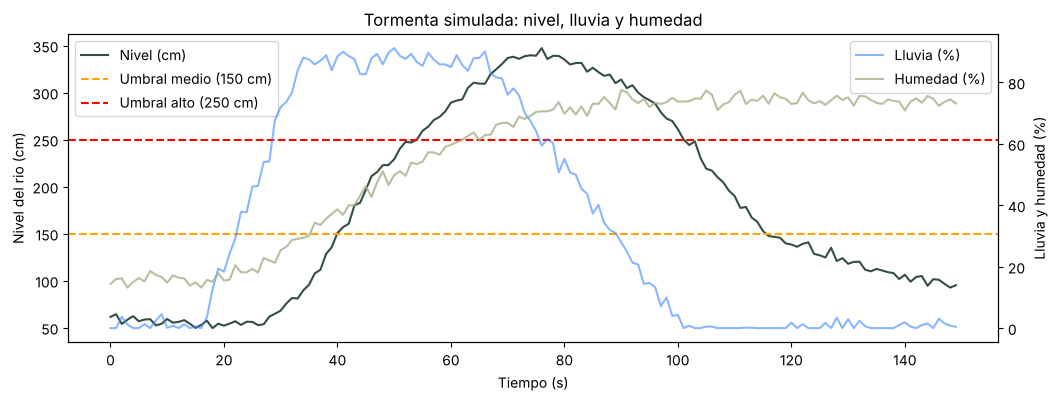

In [14]:
t0 = df[df['tormenta'] == 3]
fig, eje1 = plt.subplots(figsize=(12, 4))
eje1.plot(t0['segundo'], t0['nivel_cm'], color='#344E41', label='Nivel (cm)')
eje1.axhline(150, color='orange', linestyle='--', label='Umbral medio (150 cm)')
eje1.axhline(250, color='red', linestyle='--', label='Umbral alto (250 cm)')
eje1.set_xlabel('Tiempo (s)')
eje1.set_ylabel('Nivel del rio (cm)')
eje2 = eje1.twinx()
eje2.plot(t0['segundo'], t0['lluvia_pct'], color='#3A86FF', alpha=0.6, label='Lluvia (%)')
eje2.plot(t0['segundo'], t0['humedad_pct'], color='#A3B18A', alpha=0.8, label='Humedad (%)')
eje2.set_ylabel('Lluvia y humedad (%)')
eje1.legend(loc='upper left')
eje2.legend(loc='upper right')
plt.title('Tormenta simulada: nivel, lluvia y humedad')
plt.show()

**Comentario:** La lluvia empieza cerca del segundo 18 y el nivel empieza a subir unos 10 s después. El nivel cruza 150 cm en el segundo 40 y 250 cm en el 54, cuando la lluvia ya lleva un rato arriba de 80 %. Cuando la lluvia baja, el nivel tarda en bajar y la humedad se queda alta.

## 4.- Preparación de datos

### 4.1 Características
Las reglas solo usan el valor actual. El modelo también ve **cómo viene cambiando** el río:

| Columna | Qué es |
|---|---|
| `nivel_cm`, `lluvia_pct`, `humedad_pct` | Lectura actual |
| `cambio_10s` | Cuánto subió el nivel en los últimos 10 s |
| `cambio_30s` | Cuánto subió el nivel en los últimos 30 s |
| `lluvia_prom_30s` | Lluvia promedio de los últimos 30 s |
| `riesgo_actual` | Lo que dicen las reglas ahora |

In [15]:
HORIZONTE_S = 15
VENTANA_CORTA = 10
VENTANA_LARGA = 30
COLUMNAS = ['nivel_cm', 'lluvia_pct', 'humedad_pct', 'cambio_10s', 'cambio_30s', 'lluvia_prom_30s', 'riesgo_actual']

def agregar_caracteristicas(datos):
    datos = datos.copy()
    g = datos.groupby('tormenta')
    primero = g['nivel_cm'].transform('first')
    datos['cambio_10s'] = datos['nivel_cm'] - g['nivel_cm'].shift(VENTANA_CORTA).fillna(primero)
    datos['cambio_30s'] = datos['nivel_cm'] - g['nivel_cm'].shift(VENTANA_LARGA).fillna(primero)
    datos['lluvia_prom_30s'] = g['lluvia_pct'].transform(lambda s: s.rolling(VENTANA_LARGA, min_periods=1).mean())
    datos['riesgo_actual'] = [clasificar_riesgo(n, l, h) for n, l, h in
                              zip(datos['nivel_cm'], datos['lluvia_pct'], datos['humedad_pct'])]
    return datos

df = agregar_caracteristicas(df)
df.head(10)

,fecha_hora,tormenta,segundo,nivel_cm,lluvia_pct,humedad_pct,cambio_10s,cambio_30s,lluvia_prom_30s,riesgo_actual
0,2026-11-10 14:00:00,0,0,114.3,1.6,17.8,0.0,0.0,1.600000,0
1,2026-11-10 14:00:01,0,1,114.6,0.9,16.4,0.3,0.3,1.250000,0
2,2026-11-10 14:00:02,0,2,111.8,0.0,18.9,-2.5,-2.5,0.833333,0
3,2026-11-10 14:00:03,0,3,110.1,0.0,16.6,-4.2,-4.2,0.625000,0
4,2026-11-10 14:00:04,0,4,113.5,0.0,16.9,-0.8,-0.8,0.500000,0
5,2026-11-10 14:00:05,0,5,108.3,1.1,18.1,-6.0,-6.0,0.600000,0
6,2026-11-10 14:00:06,0,6,110.2,4.2,20.8,-4.1,-4.1,1.114286,0
7,2026-11-10 14:00:07,0,7,107.3,5.7,16.5,-7.0,-7.0,1.687500,0
8,2026-11-10 14:00:08,0,8,109.9,12.4,17.7,-4.4,-4.4,2.877778,0
9,2026-11-10 14:00:09,0,9,105.2,11.8,19.1,-9.1,-9.1,3.770000,0


### 4.2 Etiqueta: riesgo dentro de 15 segundos
Se toma el riesgo que dieron las reglas 15 lecturas después, dentro de la misma tormenta.

In [16]:
df['riesgo_futuro'] = df.groupby('tormenta')['riesgo_actual'].shift(-HORIZONTE_S)
df = df.dropna(subset=['riesgo_futuro'])
df['riesgo_futuro'] = df['riesgo_futuro'].astype(int)

print('Registros para entrenar:', df.shape[0])
print('Lecturas donde el riesgo cambia en 15 s:', round((df['riesgo_futuro'] != df['riesgo_actual']).mean() * 100, 1), '%')

Registros para entrenar: 1620
Lecturas donde el riesgo cambia en 15 s: 23.4 %


### 4.3 Balanceo de las clases

riesgo_futuro
0    68.33
1    15.56
2    16.11
Name: count, dtype: float64


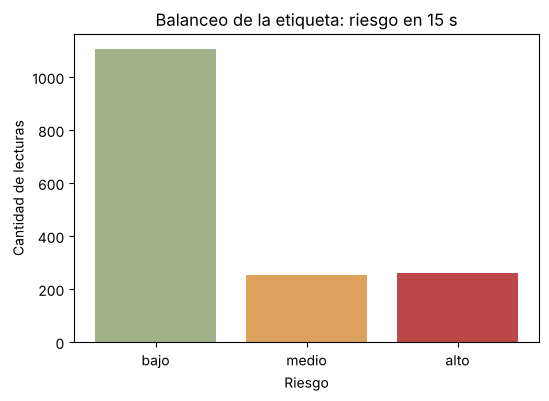

In [17]:
conteo = df['riesgo_futuro'].value_counts().sort_index()
print((conteo / conteo.sum() * 100).round(2))

plt.figure(figsize=(6, 4))
plt.bar(CLASES, conteo.values, color=['#A3B18A', '#DDA15E', '#BC4749'])
plt.title('Balanceo de la etiqueta: riesgo en 15 s')
plt.xlabel('Riesgo')
plt.ylabel('Cantidad de lecturas')
plt.show()

**Comentario:** BAJO tiene 68.3 %, MEDIO 15.6 % y ALTO 16.1 %. Las clases están desbalanceadas, por eso se usa class_weight='balanced' y se revisa sobre todo el recall de ALTO (es peor no avisar que dar una falsa alarma).

### 4.4 Correlación

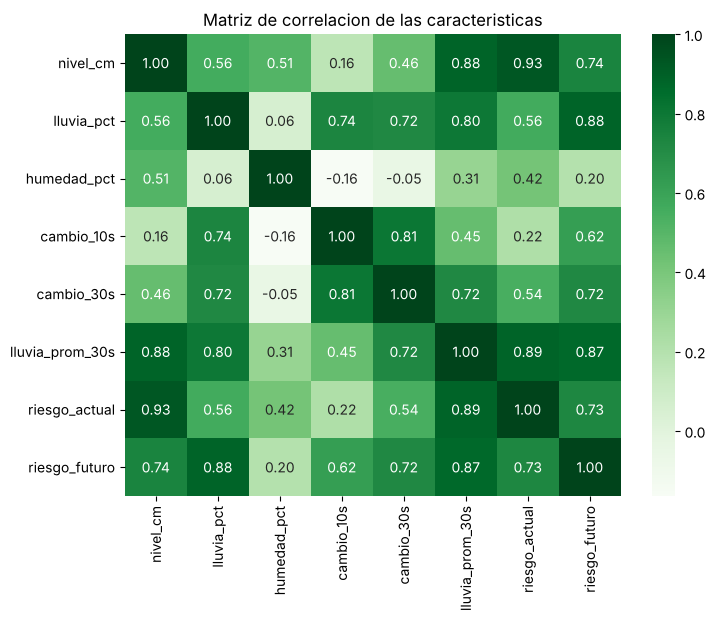

In [18]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[COLUMNAS + ['riesgo_futuro']].corr(), annot=True, fmt='.2f', cmap='Greens')
plt.title('Matriz de correlacion de las caracteristicas')
plt.show()

**Comentario:** Las que más se relacionan con el riesgo en 15 s son lluvia_pct (0.88), lluvia_prom_30s (0.87) y nivel_cm (0.74). El cambio de 30 s (0.72) se relaciona casi igual que el riesgo actual (0.73): la tendencia del río ayuda a ver lo que viene. La humedad sola casi no se relaciona (0.20).

### 4.5 División por tormentas (80 % / 20 %)
Son datos en el tiempo. Si se mezclan lecturas de la misma tormenta en entrenamiento y prueba, el modelo "ve el futuro". Por eso se separan **tormentas completas**.

In [19]:
X = df[COLUMNAS]
y = df['riesgo_futuro']
grupos = df['tormenta']

division = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMILLA)
idx_train, idx_test = next(division.split(X, y, grupos))
X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
grupos_train = grupos.iloc[idx_train]

print('Entrenamiento:', X_train.shape, '| Prueba:', X_test.shape)
print('Tormentas de prueba:', grupos.iloc[idx_test].nunique())

Entrenamiento: (1215, 7) | Prueba: (405, 7)
Tormentas de prueba: 3


### 4.6 Escalado
Solo para los modelos que usan distancias (regresión logística y KNN). `fit` solo con entrenamiento.

In [20]:
escala = StandardScaler()
X_train_esc = escala.fit_transform(X_train)
X_test_esc = escala.transform(X_test)

## 5.- Modelado

### 5.1 Modelo 1: Regresión logística
**¿Cómo funciona?** Calcula una probabilidad para cada clase con una suma ponderada de las características y elige la más alta.

In [21]:
# Crear el modelo
modelo1 = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEMILLA)
# Entrenar
modelo1.fit(X_train_esc, y_train)
# Predecir
pred1 = modelo1.predict(X_test_esc)
prob1 = modelo1.predict_proba(X_test_esc)
# Metricas
print(classification_report(y_test, pred1, target_names=CLASES, digits=3))

              precision    recall  f1-score   support

        bajo      0.978     0.919     0.948       285
       medio      0.692     0.923     0.791        78
        alto      1.000     0.786     0.880        42

    accuracy                          0.906       405
   macro avg      0.890     0.876     0.873       405
weighted avg      0.925     0.906     0.910       405



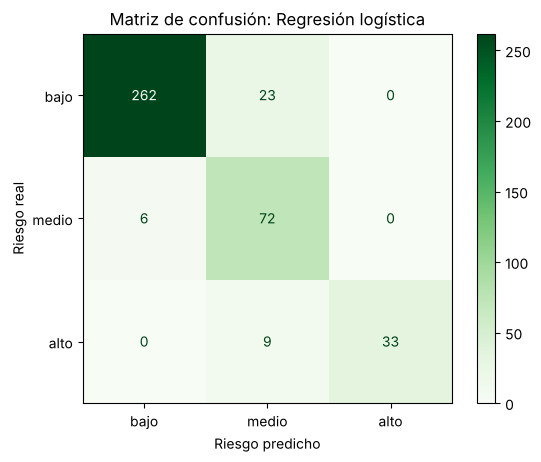

In [22]:
# Matriz de confusion
ConfusionMatrixDisplay(confusion_matrix(y_test, pred1), display_labels=CLASES).plot(cmap='Greens', values_format='d')
plt.title('Matriz de confusión: Regresión logística')
plt.xlabel('Riesgo predicho')
plt.ylabel('Riesgo real')
plt.show()

**Comentario:** Acierta el 90.6 % de las lecturas y detecta el 78.6 % de los casos ALTO. Su error más común es dar MEDIO cuando era BAJO (23 lecturas).

### 5.2 Modelo 2: KNN
**¿Cómo funciona?** Busca las 15 lecturas de entrenamiento más parecidas y elige el riesgo que más se repite entre ellas.

In [23]:
# Crear el modelo
modelo2 = KNeighborsClassifier(n_neighbors=15)
# Entrenar
modelo2.fit(X_train_esc, y_train)
# Predecir
pred2 = modelo2.predict(X_test_esc)
prob2 = modelo2.predict_proba(X_test_esc)
# Metricas
print(classification_report(y_test, pred2, target_names=CLASES, digits=3))

              precision    recall  f1-score   support

        bajo      0.934     1.000     0.966       285
       medio      0.937     0.756     0.837        78
        alto      0.973     0.857     0.911        42

    accuracy                          0.938       405
   macro avg      0.948     0.871     0.905       405
weighted avg      0.939     0.938     0.936       405



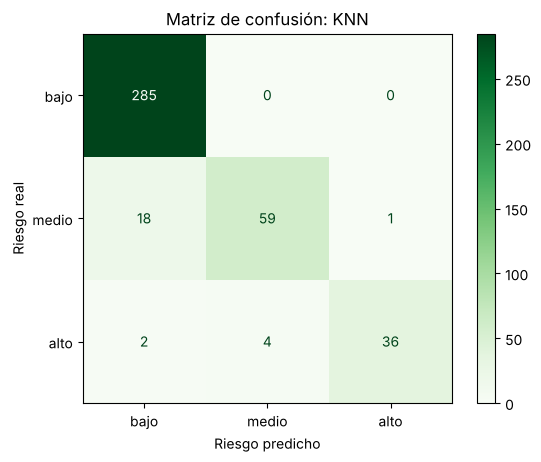

In [24]:
# Matriz de confusion
ConfusionMatrixDisplay(confusion_matrix(y_test, pred2), display_labels=CLASES).plot(cmap='Greens', values_format='d')
plt.title('Matriz de confusión: KNN')
plt.xlabel('Riesgo predicho')
plt.ylabel('Riesgo real')
plt.show()

**Comentario:** Exactitud de 93.8 % y recall de ALTO de 85.7 %. Es el que menos recupera la clase MEDIO (75.6 %).

### 5.3 Modelo 3: Naive Bayes
**¿Cómo funciona?** Usa probabilidades suponiendo que cada característica es independiente de las demás.

In [25]:
# Crear el modelo
modelo3 = GaussianNB()
# Entrenar
modelo3.fit(X_train, y_train)
# Predecir
pred3 = modelo3.predict(X_test)
prob3 = modelo3.predict_proba(X_test)
# Metricas
print(classification_report(y_test, pred3, target_names=CLASES, digits=3))

              precision    recall  f1-score   support

        bajo      0.978     0.916     0.946       285
       medio      0.683     0.910     0.780        78
        alto      0.971     0.786     0.868        42

    accuracy                          0.901       405
   macro avg      0.877     0.871     0.865       405
weighted avg      0.920     0.901     0.906       405



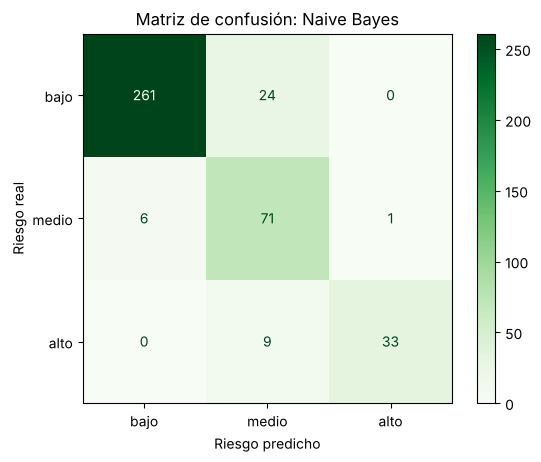

In [26]:
# Matriz de confusion
ConfusionMatrixDisplay(confusion_matrix(y_test, pred3), display_labels=CLASES).plot(cmap='Greens', values_format='d')
plt.title('Matriz de confusión: Naive Bayes')
plt.xlabel('Riesgo predicho')
plt.ylabel('Riesgo real')
plt.show()

**Comentario:** Es el más bajo: exactitud de 90.1 % y F1 de 0.865. Confunde mucho BAJO con MEDIO (precisión de MEDIO 68.3 %) y detecta el 78.6 % de los ALTO.

### 5.4 Modelo 4: Árbol de decisión
**¿Cómo funciona?** Hace preguntas del tipo "¿el nivel es mayor a 230 cm?" hasta llegar a una respuesta.

In [27]:
# Crear el modelo
modelo4 = DecisionTreeClassifier(max_depth=7, class_weight='balanced', random_state=SEMILLA)
# Entrenar
modelo4.fit(X_train, y_train)
# Predecir
pred4 = modelo4.predict(X_test)
prob4 = modelo4.predict_proba(X_test)
# Metricas
print(classification_report(y_test, pred4, target_names=CLASES, digits=3))

              precision    recall  f1-score   support

        bajo      0.989     0.930     0.958       285
       medio      0.740     0.910     0.816        78
        alto      0.902     0.881     0.892        42

    accuracy                          0.921       405
   macro avg      0.877     0.907     0.889       405
weighted avg      0.932     0.921     0.924       405



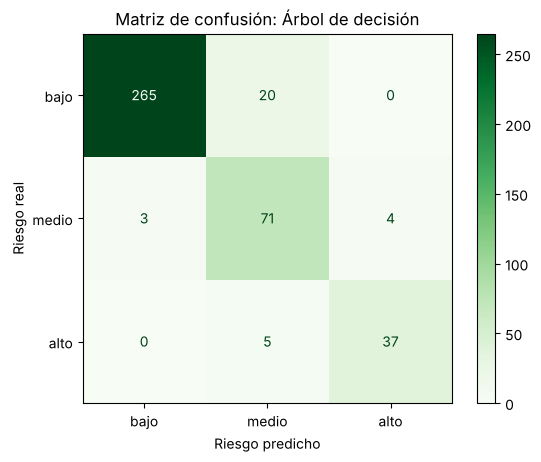

In [28]:
# Matriz de confusion
ConfusionMatrixDisplay(confusion_matrix(y_test, pred4), display_labels=CLASES).plot(cmap='Greens', values_format='d')
plt.title('Matriz de confusión: Árbol de decisión')
plt.xlabel('Riesgo predicho')
plt.ylabel('Riesgo real')
plt.show()

**Comentario:** Exactitud de 92.1 % y recall de ALTO de 88.1 %, de los más altos, pero da muchas falsas alarmas de MEDIO (precisión de MEDIO 74.0 %).

### 5.5 Modelo 5: Random Forest
**¿Cómo funciona?** Entrena 100 árboles con partes distintas de los datos y gana la respuesta que más árboles votan.

In [29]:
# Crear el modelo
modelo5 = RandomForestClassifier(n_estimators=100, max_depth=8, class_weight='balanced', random_state=SEMILLA)
# Entrenar
modelo5.fit(X_train, y_train)
# Predecir
pred5 = modelo5.predict(X_test)
prob5 = modelo5.predict_proba(X_test)
# Metricas
print(classification_report(y_test, pred5, target_names=CLASES, digits=3))

              precision    recall  f1-score   support

        bajo      0.975     0.954     0.965       285
       medio      0.788     0.859     0.822        78
        alto      0.902     0.881     0.892        42

    accuracy                          0.928       405
   macro avg      0.889     0.898     0.893       405
weighted avg      0.931     0.928     0.930       405



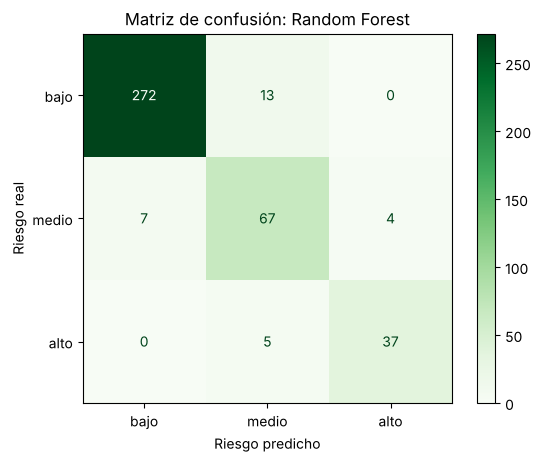

In [30]:
# Matriz de confusion
ConfusionMatrixDisplay(confusion_matrix(y_test, pred5), display_labels=CLASES).plot(cmap='Greens', values_format='d')
plt.title('Matriz de confusión: Random Forest')
plt.xlabel('Riesgo predicho')
plt.ylabel('Riesgo real')
plt.show()

**Comentario:** Exactitud de 92.8 % y recall de ALTO de 88.1 %. Mejora un poco al árbol solo porque junta el voto de 100 árboles.

### 5.6 Modelo 6: XGBoost
**¿Cómo funciona?** Entrena árboles uno tras otro; cada árbol nuevo corrige los errores de los anteriores.

In [31]:
# Crear el modelo
modelo6 = XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.1, random_state=SEMILLA)
# Entrenar
modelo6.fit(X_train, y_train, sample_weight=compute_sample_weight('balanced', y_train))
# Predecir
pred6 = modelo6.predict(X_test)
prob6 = modelo6.predict_proba(X_test)
# Metricas
print(classification_report(y_test, pred6, target_names=CLASES, digits=3))

              precision    recall  f1-score   support

        bajo      0.982     0.982     0.982       285
       medio      0.869     0.936     0.901        78
        alto      1.000     0.857     0.923        42

    accuracy                          0.960       405
   macro avg      0.951     0.925     0.936       405
weighted avg      0.962     0.960     0.961       405



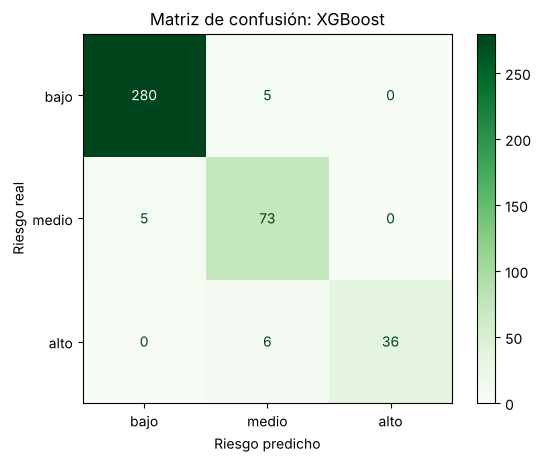

In [32]:
# Matriz de confusion
ConfusionMatrixDisplay(confusion_matrix(y_test, pred6), display_labels=CLASES).plot(cmap='Greens', values_format='d')
plt.title('Matriz de confusión: XGBoost')
plt.xlabel('Riesgo predicho')
plt.ylabel('Riesgo real')
plt.show()

**Comentario:** Es el mejor: exactitud de 96.0 % y F1 de 0.936. De 42 lecturas que de verdad iban a ser ALTO, acertó 36 y las otras 6 las dio como MEDIO; ninguna como BAJO.

## 6.- Comparación de modelos

### 6.1 Tabla de métricas
El AUC se calcula para la clase ALTO contra las demás, que es la que importa no fallar.

In [33]:
nombres = ['Regresión logística', 'KNN', 'Naive Bayes', 'Árbol de decisión', 'Random Forest', 'XGBoost']
modelos = [modelo1, modelo2, modelo3, modelo4, modelo5, modelo6]
predicciones = [pred1, pred2, pred3, pred4, pred5, pred6]
probabilidades = [prob1, prob2, prob3, prob4, prob5, prob6]
usa_escala = [True, True, False, False, False, False]

filas = []
for nombre, pred, prob in zip(nombres, predicciones, probabilidades):
    filas.append([nombre,
                  accuracy_score(y_test, pred),
                  f1_score(y_test, pred, average='macro'),
                  recall_score(y_test, pred, labels=[2], average='macro'),
                  roc_auc_score((y_test == 2).astype(int), prob[:, 2])])
tabla = pd.DataFrame(filas, columns=['Modelo', 'Exactitud', 'F1 macro', 'Recall ALTO', 'AUC ALTO']).set_index('Modelo')
tabla.round(3)

,Exactitud,F1 macro,Recall ALTO,AUC ALTO
Modelo,,,,
Regresión logística,0.906,0.873,0.786,0.994
KNN,0.938,0.905,0.857,0.963
Naive Bayes,0.901,0.865,0.786,0.984
Árbol de decisión,0.921,0.889,0.881,0.985
Random Forest,0.928,0.893,0.881,0.994
XGBoost,0.960,0.936,0.857,0.988


### 6.2 Curva ROC (ALTO contra el resto)

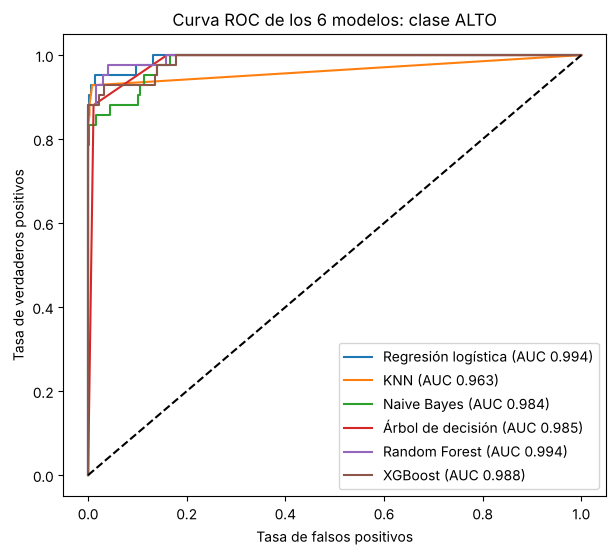

In [34]:
plt.figure(figsize=(7, 6))
for nombre, prob in zip(nombres, probabilidades):
    fpr, tpr, _ = roc_curve((y_test == 2).astype(int), prob[:, 2])
    auc = roc_auc_score((y_test == 2).astype(int), prob[:, 2])
    plt.plot(fpr, tpr, label=nombre + ' (AUC ' + str(round(auc, 3)) + ')')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('Curva ROC de los 6 modelos: clase ALTO')
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos')
plt.legend()
plt.show()

**Comentario:** Las 6 curvas quedan pegadas a la esquina de arriba a la izquierda, así que todos separan bien ALTO del resto. Regresión logística y Random Forest tienen el AUC más alto (0.994), XGBoost queda en 0.988 y KNN es el más bajo (0.963).

### 6.3 Validación cruzada por tormentas (5 grupos)
Se repite el entrenamiento 5 veces con tormentas distintas para ver si el resultado es estable.

In [35]:
kfold = GroupKFold(n_splits=5)
X_train_np = X_train.values
for nombre, modelo, esc in zip(nombres, modelos, usa_escala):
    datos = X_train_esc if esc else X_train_np
    puntaje = cross_val_score(modelo, datos, y_train, groups=grupos_train, cv=kfold, scoring='f1_macro')
    print(nombre.ljust(20), 'F1 macro promedio:', round(puntaje.mean(), 3), '+/-', round(puntaje.std(), 3))

Regresión logística  F1 macro promedio: 0.862 +/- 0.092
KNN                  F1 macro promedio: 0.773 +/- 0.167
Naive Bayes          F1 macro promedio: 0.828 +/- 0.092
Árbol de decisión    F1 macro promedio: 0.854 +/- 0.089


Random Forest        F1 macro promedio: 0.818 +/- 0.147


XGBoost              F1 macro promedio: 0.813 +/- 0.155


**Comentario:** Con 5 grupos de tormentas distintas los resultados cambian mucho: regresión logística queda arriba (F1 0.862 ± 0.092), XGBoost baja a 0.813 ± 0.155 y KNN es el más bajo (0.773 ± 0.167). La variación es grande porque son solo 12 tormentas: en cada grupo se prueban 2 o 3 y no siempre hay alguna que llegue a ALTO.

### 6.4 Mejor modelo

In [36]:
# El de mejor F1 macro
mejor = tabla['F1 macro'].idxmax()
pos = nombres.index(mejor)
modelo_final = modelos[pos]
escala_final = usa_escala[pos]
print('Mejor modelo:', mejor)
print(tabla.loc[mejor].round(3))

Mejor modelo: XGBoost
Exactitud      0.960
F1 macro       0.936
Recall ALTO    0.857
AUC ALTO       0.988
Name: XGBoost, dtype: float64


### 6.5 IA contra las reglas
Las reglas, aplicadas al momento actual, también se pueden ver como un "modelo" que predice que en 15 s todo seguirá igual. La IA tiene que ganarle.

In [37]:
print('Reglas (riesgo actual):')
print(classification_report(y_test, X_test['riesgo_actual'], target_names=CLASES, digits=3))
print(mejor + ':')
print(classification_report(y_test, predicciones[pos], target_names=CLASES, digits=3))

Reglas (riesgo actual):
              precision    recall  f1-score   support

        bajo      0.895     0.895     0.895       285
       medio      0.538     0.538     0.538        78
        alto      0.643     0.643     0.643        42

    accuracy                          0.800       405
   macro avg      0.692     0.692     0.692       405
weighted avg      0.800     0.800     0.800       405

XGBoost:
              precision    recall  f1-score   support

        bajo      0.982     0.982     0.982       285
       medio      0.869     0.936     0.901        78
        alto      1.000     0.857     0.923        42

    accuracy                          0.960       405
   macro avg      0.951     0.925     0.936       405
weighted avg      0.962     0.960     0.961       405



In [38]:
# Segundos que la IA avisa ALTO antes que las reglas, por tormenta
prueba = df.iloc[idx_test].copy()
prueba['pred'] = predicciones[pos]
segundos = []
for _, t in prueba.groupby('tormenta'):
    t = t.reset_index(drop=True)
    if (t['riesgo_actual'] == 2).any() and (t['pred'] == 2).any():
        segundos.append(t.index[t['riesgo_actual'] == 2][0] - t.index[t['pred'] == 2][0])
segundos = np.array(segundos)
print('Tormentas de prueba que llegan a ALTO:', len(segundos))
print('La IA avisa antes en', (segundos > 0).sum(), 'de', len(segundos))
print('Anticipacion: mediana', np.median(segundos), 's | promedio', round(segundos.mean(), 1), 's')

Tormentas de prueba que llegan a ALTO: 1
La IA avisa antes en 1 de 1
Anticipacion: mediana 10.0 s | promedio 10.0 s


**Comentario:** Si se usan las reglas para adivinar el riesgo en 15 s, sacan F1 macro de 0.692 y recall de ALTO de 0.643. XGBoost sube a 0.936 y 0.857. De las 3 tormentas de prueba solo 1 llega a ALTO, y ahí la IA avisa 10 s antes que las reglas.

### 6.6 Ejemplo en el tiempo

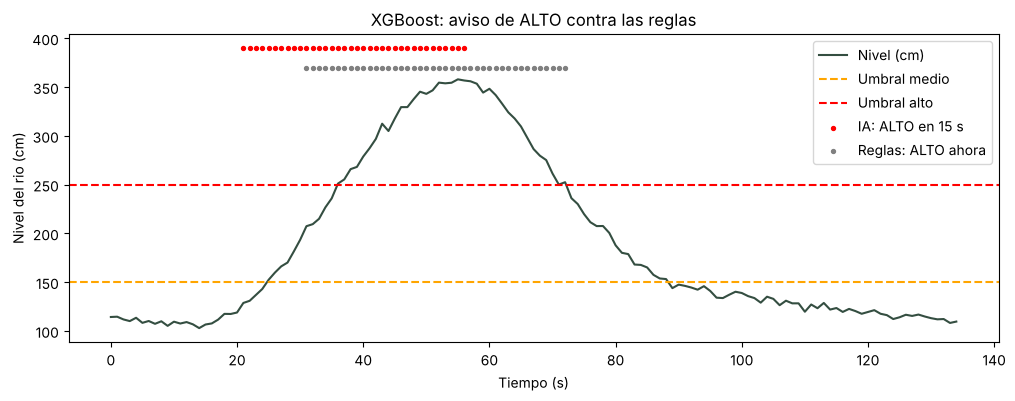

In [39]:
# Una tormenta de prueba que llega a ALTO
num = [k for k, t in prueba.groupby('tormenta') if (t['riesgo_actual'] == 2).any()][0]
t = prueba[prueba['tormenta'] == num]
plt.figure(figsize=(12, 4))
plt.plot(t['segundo'], t['nivel_cm'], color='#344E41', label='Nivel (cm)')
plt.axhline(150, color='orange', linestyle='--', label='Umbral medio')
plt.axhline(250, color='red', linestyle='--', label='Umbral alto')
plt.scatter(t['segundo'][t['pred'] == 2], [390] * (t['pred'] == 2).sum(), color='red', s=8, label='IA: ALTO en 15 s')
plt.scatter(t['segundo'][t['riesgo_actual'] == 2], [370] * (t['riesgo_actual'] == 2).sum(), color='gray', s=8, label='Reglas: ALTO ahora')
plt.title(mejor + ': aviso de ALTO contra las reglas')
plt.xlabel('Tiempo (s)')
plt.ylabel('Nivel del rio (cm)')
plt.legend(loc='upper right')
plt.show()

**Comentario:** Los puntos rojos (IA) empiezan en el segundo 21, cuando el nivel todavía va en 129 cm pero subiendo rápido; los grises (reglas) hasta el segundo 31. La IA también deja de marcar ALTO antes (segundo 56 contra 72), porque ve que el río ya va bajando.

## 7.- Predicción con una lectura nueva

La IA necesita las lecturas anteriores para calcular los cambios, así que guarda un historial de los últimos 30 s. Si cambia de dónde vienen los datos (sensores o tablero) o pasan más de 5 s sin datos, empieza de cero.

In [40]:
historial = []
estado_ia = {'fuente': None, 't': 0}

def predecir_lectura(lectura):
    global historial
    modo = lectura.get('modo', 'auto')
    # De donde vienen los datos: sensores o valores del tablero (simulados)
    simulado = lectura.get('simulado', modo == 'manual')
    fuente = 'tablero' if simulado else 'sensores'
    ahora = time.time()
    # Si cambio la fuente o hubo un hueco, el historial ya no sirve
    if fuente != estado_ia['fuente'] or ahora - estado_ia['t'] > 5:
        historial = []
    estado_ia['fuente'] = fuente
    estado_ia['t'] = ahora

    historial.append({'tormenta': 0, 'nivel_cm': float(lectura['nivel_cm']),
                      'lluvia_pct': float(lectura['lluvia_pct']), 'humedad_pct': float(lectura['humedad_pct'])})
    historial = historial[-(VENTANA_LARGA + 1):]

    tabla_h = agregar_caracteristicas(pd.DataFrame(historial))
    x = tabla_h[COLUMNAS].iloc[[-1]]
    if escala_final:
        x = escala.transform(x)
    prob = modelo_final.predict_proba(x)[0]
    clase = int(np.argmax(prob))
    return {'riesgo_15s': clase,
            'prob': [round(float(p), 3) for p in prob],
            'riesgo_ahora': int(tabla_h['riesgo_actual'].iloc[-1]),
            'modo': modo,
            'horizonte_s': HORIZONTE_S,
            'modelo': mejor,
            't': int(ahora)}

# Ejemplo: el rio sube 8 cm por segundo con lluvia fuerte (las reglas todavia dicen MEDIO)
for nivel in range(110, 200, 8):
    r = predecir_lectura({'nivel_cm': nivel, 'lluvia_pct': 85, 'humedad_pct': 90, 'modo': 'auto'})
print('Lectura actual: nivel', nivel, 'cm, lluvia 85 %, humedad 90 %')
print('Reglas ahora:', CLASES[r['riesgo_ahora']], '| IA en 15 s:', CLASES[r['riesgo_15s']], '| probabilidades:', r['prob'])

Lectura actual: nivel 198 cm, lluvia 85 %, humedad 90 %
Reglas ahora: medio | IA en 15 s: alto | probabilidades: [0.0, 0.0, 1.0]


## 8.- Guardar el modelo

In [41]:
joblib.dump({'modelo': modelo_final, 'escala': escala if escala_final else None,
             'columnas': COLUMNAS, 'horizonte_s': HORIZONTE_S, 'nombre': mejor}, 'modelo_rio.joblib')
print('Guardado: modelo_rio.joblib')

Guardado: modelo_rio.joblib


## 9.- IA en vivo con el nodo (MQTT)
El cuaderno se conecta al mismo broker que el ESP32, Node-RED y el tablero:
1. Se suscribe a `ucol-eq1/rio/nodo1/datos` (lecturas del nodo cada segundo).
2. Con cada lectura predice el riesgo en 15 s.
3. Publica el resultado en `ucol-eq1/rio/nodo1/ia`. El tablero (maquetaiot.eparedes.dev) lo muestra en la tarjeta **Pronóstico IA**.

Predice en los 3 modos, pero solo en **modo IA** el ESP32 obedece su pronóstico:
- **Automático:** la IA solo avisa en el tablero; deciden las reglas.
- **Manual:** la IA predice con los valores del tablero; la compuerta la mueve el usuario.
- **IA:** el ESP32 usa el riesgo de la IA para el LED, el buzzer y la compuerta. Con *Simular crecida* se ve cómo abre la compuerta antes que las reglas.

Protecciones del ESP32 en modo IA:
- Si no llega un pronóstico en 5 s (Colab apagado o sin internet), vuelven a decidir las reglas.
- Si el nivel pasa de 250 cm, el riesgo es alto aunque la IA diga otra cosa.

Colab se desconecta si la pestaña se queda inactiva mucho tiempo: durante la demostración deja esta pestaña abierta.

### 9.1 Datos de conexión
Pon `CONECTAR = True` para conectarte. La clave se pide al ejecutar (no se guarda en el cuaderno).

In [42]:
CONECTAR = False
BROKER = 'mqtt.eparedes.dev'
PUERTO = 443
RUTA = '/mqtt'
USUARIO = 'maquetaweb'
TOPICO_DATOS = 'ucol-eq1/rio/nodo1/datos'
TOPICO_IA = 'ucol-eq1/rio/nodo1/ia'
MINUTOS = 30                  # tiempo que se queda escuchando

if CONECTAR:
    from getpass import getpass
    CLAVE = getpass('Clave del usuario ' + USUARIO + ': ')

### 9.2 Prueba sin broker
Un nodo simulado manda una tormenta nueva lectura por lectura, como lo haría el ESP32.

In [43]:
nodo_falso = generar(1, 7)
historial = []
estado_ia['fuente'] = None
resultados = []
for _, fila in nodo_falso.iterrows():
    r = predecir_lectura({'nivel_cm': fila['nivel_cm'], 'lluvia_pct': fila['lluvia_pct'],
                          'humedad_pct': fila['humedad_pct'], 'modo': 'auto'})
    resultados.append([int(fila['segundo']), fila['nivel_cm'], CLASES[r['riesgo_ahora']], CLASES[r['riesgo_15s']], r['prob'][2]])
vivo = pd.DataFrame(resultados, columns=['segundo', 'nivel_cm', 'reglas_ahora', 'ia_15s', 'prob_alto'])

# Momentos donde la IA ya ve venir un riesgo mayor que el de ahora
vivo[vivo['ia_15s'].map(CLASES.index) > vivo['reglas_ahora'].map(CLASES.index)].head(10)

,segundo,nivel_cm,reglas_ahora,ia_15s,prob_alto
26,26,109.8,bajo,medio,0.025
27,27,108.0,bajo,medio,0.009
28,28,105.7,bajo,medio,0.011
29,29,106.5,bajo,medio,0.033
30,30,104.3,bajo,medio,0.038
31,31,112.5,bajo,medio,0.001
32,32,107.9,bajo,medio,0.185
33,33,108.9,bajo,alto,0.531
34,34,109.6,bajo,alto,0.511
35,35,113.5,bajo,alto,0.910


**¿Cuándo abre la compuerta?** Se repite la lógica del ESP32: abre con riesgo alto y cierra cuando ya no es alto y el nivel baja de 150 cm. En modo automático el riesgo es el de las reglas; en modo IA es el de la IA (con el límite de seguridad de 250 cm) y la compuerta se queda abierta al menos 15 s desde el último ALTO, para que no abra y cierre si la IA cambia de opinión.

Modo automatico (reglas): la compuerta abre en el segundo 46
Modo IA: la compuerta abre en el segundo 33
La IA abre 13 s antes
Veces que abre la compuerta: reglas 1 | IA 1


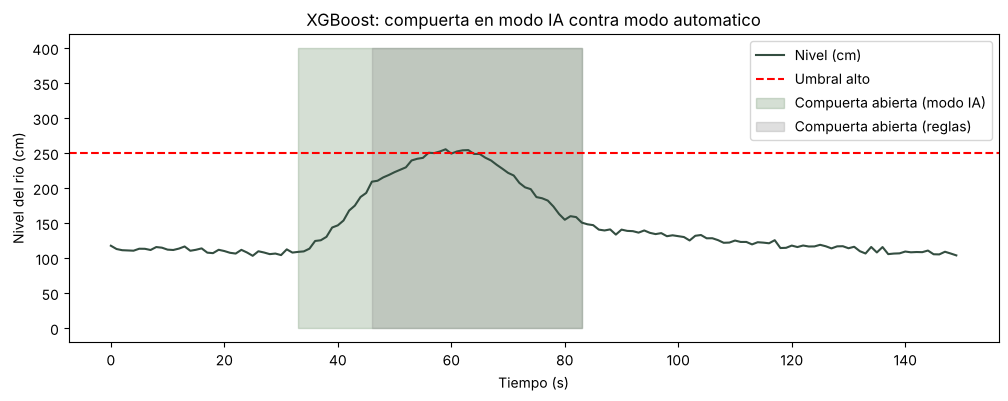

In [44]:
def segundos_abierta(riesgos, niveles, espera_s=0):
    abierta = False
    ultimo_alto = -1000
    estados = []
    for s, (r, n) in enumerate(zip(riesgos, niveles)):
        if r == 2:
            abierta = True
            ultimo_alto = s
        if r != 2 and n < 150 and s - ultimo_alto >= espera_s:
            abierta = False
        estados.append(abierta)
    return estados

riesgo_reglas = vivo['reglas_ahora'].map(CLASES.index)
riesgo_ia = vivo['ia_15s'].map(CLASES.index)
riesgo_ia = np.where(vivo['nivel_cm'] > 250, 2, riesgo_ia)     # limite de seguridad
vivo['compuerta_reglas'] = segundos_abierta(riesgo_reglas, vivo['nivel_cm'])
vivo['compuerta_ia'] = segundos_abierta(riesgo_ia, vivo['nivel_cm'], espera_s=15)

abre_reglas = vivo['segundo'][vivo['compuerta_reglas']].min()
abre_ia = vivo['segundo'][vivo['compuerta_ia']].min()
print('Modo automatico (reglas): la compuerta abre en el segundo', abre_reglas)
print('Modo IA: la compuerta abre en el segundo', abre_ia)
print('La IA abre', abre_reglas - abre_ia, 's antes')
print('Veces que abre la compuerta: reglas', (vivo['compuerta_reglas'].astype(int).diff() == 1).sum() + int(vivo['compuerta_reglas'].iloc[0]),
      '| IA', (vivo['compuerta_ia'].astype(int).diff() == 1).sum() + int(vivo['compuerta_ia'].iloc[0]))

plt.figure(figsize=(12, 4))
plt.plot(vivo['segundo'], vivo['nivel_cm'], color='#344E41', label='Nivel (cm)')
plt.axhline(250, color='red', linestyle='--', label='Umbral alto')
plt.fill_between(vivo['segundo'], 0, 400, where=vivo['compuerta_ia'], color='#588157', alpha=0.25, label='Compuerta abierta (modo IA)')
plt.fill_between(vivo['segundo'], 0, 400, where=vivo['compuerta_reglas'], color='gray', alpha=0.25, label='Compuerta abierta (reglas)')
plt.title(mejor + ': compuerta en modo IA contra modo automatico')
plt.xlabel('Tiempo (s)')
plt.ylabel('Nivel del rio (cm)')
plt.legend(loc='upper right')
plt.show()

### 9.3 Conectar al broker
Deja esta celda corriendo durante la demostración. Para que la IA controle el nodo, en el tablero elige **IA** en el selector de modo. La columna *decide* dice quién mandó en el ESP32: `ia`, `reglas`, `respaldo` (sin pronóstico) o `seguridad` (más de 250 cm).

In [45]:
import paho.mqtt.client as mqtt
import random
import ssl
from IPython.display import clear_output

registro = []     # predicciones publicadas
lecturas = []     # lecturas reales recibidas
SESION = int(time.time())

def al_conectar(cliente, datos, banderas, codigo, propiedades):
    if codigo.is_failure:
        print('El broker rechazo la conexion:', codigo)
    else:
        print('Conectado al broker')
        cliente.subscribe(TOPICO_DATOS, qos=0)

def al_recibir(cliente, datos, mensaje):
    if mensaje.retain:                # lectura vieja guardada por el broker
        return
    lectura = json.loads(mensaje.payload.decode())
    resultado = predecir_lectura(lectura)
    cliente.publish(TOPICO_IA, json.dumps(resultado), qos=0)
    registro.append({**resultado, 'decide': lectura.get('decide', '-')})
    lecturas.append({'sesion': SESION, 'segundo': len(lecturas), 'nivel_cm': lectura['nivel_cm'],
                     'lluvia_pct': lectura['lluvia_pct'], 'humedad_pct': lectura['humedad_pct'],
                     'modo': lectura.get('modo', 'auto')})

def escuchar():
    cliente = mqtt.Client(mqtt.CallbackAPIVersion.VERSION2,
                          client_id='colab-ia-' + str(random.randint(1000, 9999)), transport='websockets')
    cliente.ws_set_options(path=RUTA)
    cliente.tls_set(cert_reqs=ssl.CERT_REQUIRED)
    cliente.username_pw_set(USUARIO, CLAVE)
    cliente.on_connect = al_conectar
    cliente.on_message = al_recibir
    cliente.connect(BROKER, PUERTO, keepalive=30)
    cliente.loop_start()
    fin = time.time() + MINUTOS * 60
    try:
        while time.time() < fin:
            time.sleep(5)
            clear_output(wait=True)
            print('Predicciones publicadas:', len(registro))
            for r in registro[-5:]:
                print(time.strftime('%H:%M:%S', time.localtime(r['t'])), '| modo', r['modo'],
                      '| decide:', r['decide'], '| reglas ahora:', CLASES[r['riesgo_ahora']],
                      '| IA en 15 s:', CLASES[r['riesgo_15s']], '| prob. alto:', r['prob'][2])
    except KeyboardInterrupt:
        print('Detenido')
    finally:
        cliente.loop_stop()
        cliente.disconnect()
        print('Desconectado')

if CONECTAR:
    escuchar()
else:
    print('CONECTAR = False: pon True en la celda 9.1 para escuchar al nodo.')

CONECTAR = False: pon True en la celda 9.1 para escuchar al nodo.


### 9.4 Guardar las lecturas reales
Sirven para volver a entrenar con datos de la maqueta (sección 2.3).

In [46]:
if lecturas:
    pd.DataFrame(lecturas).to_csv('lecturas_reales.csv', index=False)
    print('Guardadas', len(lecturas), 'lecturas en lecturas_reales.csv')
else:
    print('Todavia no hay lecturas reales.')

Todavia no hay lecturas reales.


## 10.- Conclusión

- Se entrenaron 6 modelos de clasificación con el dataset `dataset_nodo_rio.csv`: 1,808 lecturas de 12 tormentas simuladas. Después de limpiar 8 mensajes repetidos y 19 lecturas vacías quedaron 1,800, y 1,620 con etiqueta. Se separaron tormentas completas para la prueba para que el modelo no viera el futuro.
- El mejor en la prueba fue **XGBoost**: exactitud 0.960, F1 macro 0.936, recall de ALTO 0.857 y AUC 0.988. Cumple la meta de F1 ≥ 0.85, pero no la de recall de ALTO ≥ 0.90: de 42 lecturas ALTO acertó 36 y las otras 6 las dio como MEDIO (ninguna como BAJO).
- Con pocos datos los resultados dependen mucho de qué tormentas quedan en la prueba: solo 1 de las 3 tormentas de prueba llega a ALTO, y en la validación cruzada XGBoost baja a 0.813 ± 0.155 mientras la regresión logística queda en 0.862. Para que el modelo sea más confiable hacen falta más tormentas o las lecturas reales del nodo (sección 9.4).
- Contra las reglas del nodo, la IA sube el F1 de 0.692 a 0.936 y en la tormenta de prueba avisa ALTO 10 s antes. Las reglas solo ven el momento actual; la IA también ve cómo viene cambiando el río.
- La IA corre en vivo desde Colab: recibe las lecturas del ESP32 por MQTT y publica su pronóstico en `ucol-eq1/rio/nodo1/ia`. En **modo IA** el ESP32 usa ese pronóstico para el LED, el buzzer y la compuerta; en la tormenta de la sección 9.2 la compuerta abrió 13 s antes que con las reglas.
- El nodo no depende por completo de la IA: si no llega un pronóstico en 5 s vuelven las reglas, y arriba de 250 cm el riesgo es alto aunque la IA diga otra cosa.